In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
df=pd.read_csv(r"C:\Users\HP\Desktop\Dataset_Air_Bnb.csv")

C:\Users\HP\AppData\Local\Temp\ipykernel_16780\3106960896.py:1: DtypeWarning: Columns (0: license) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(r"C:\Users\HP\Desktop\Dataset_Air_Bnb.csv")


In [4]:
df.head()

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,07-05-2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


CHECK THE COLUMN NAMES IN DATASET

In [5]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='str')

CHECK FOR MISSING VALUES

In [7]:
df.isnull().sum()

id                                     0
NAME                                 250
host id                                0
host_identity_verified               289
host name                            406
neighbourhood group                   29
neighbourhood                         16
lat                                    8
long                                   8
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    214
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15893
reviews per month                  15879
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [10]:
# Convert 'last review' to datetime and handle errors 
df['last review'] = pd.to_datetime(df['last review'], errors='coerce') 


# Fill missing values 
df.fillna({'reviews per month': 0, 'last review': df['last review'].min()}, inplace=True)


# Drop records with missing 'name' or 'host name' 
df.dropna(subset=['NAME', 'host name'], inplace=True)

In [11]:
print(df.isnull().sum())

id                                     0
NAME                                   0
host id                                0
host_identity_verified               276
host name                              0
neighbourhood group                   26
neighbourhood                         16
lat                                    8
long                                   8
country                              526
country code                         122
instant_bookable                      96
cancellation_policy                   70
room type                              0
Construction year                    200
price                                239
service fee                          268
minimum nights                       403
number of reviews                    182
last review                            0
reviews per month                      0
review rate number                   314
calculated host listings count       318
availability 365                     420
house_rules     

CORRECT DATA TYPE

Ensure that all columns have the correct data types.

In [13]:
# Remove dollar signs and convert to float 
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float) 
df['service fee'] = df['service fee'].replace('[\$,]', '', regex=True).astype(float)

<>:2: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:3: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:2: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:3: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
C:\Users\HP\AppData\Local\Temp\ipykernel_16780\902270280.py:2: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
C:\Users\HP\AppData\Local\Temp\ipykernel_16780\902270280.py:3: SyntaxWarning: "\$" is an invalid escape

REMOVE DUPLICATES

In [14]:
df.drop_duplicates(inplace=True)

CONFIRM DATA CLEANING

In [15]:
print(df.info())

<class 'pandas.DataFrame'>
Index: 101410 entries, 0 to 102057
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              101410 non-null  int64         
 1   NAME                            101410 non-null  str           
 2   host id                         101410 non-null  int64         
 3   host_identity_verified          101134 non-null  str           
 4   host name                       101410 non-null  str           
 5   neighbourhood group             101384 non-null  str           
 6   neighbourhood                   101394 non-null  str           
 7   lat                             101402 non-null  float64       
 8   long                            101402 non-null  float64       
 9   country                         100884 non-null  str           
 10  country code                    101288 non-null  str           
 11  ins

In [ ]:
DELETING COLUMNS THAT ARE NOT REQUIRED

In [16]:
df = df.drop(columns=["license", "house_rules"], errors='ignore')  

DESCRIPTICE ANALYSIS

In [17]:
df.describe()

,id,host id,lat,long,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365
count,1.014100e+05,1.014100e+05,101402.000000,101402.000000,101210.000000,101171.000000,101142.000000,101016.000000,101228.000000,101410,101410.000000,101103.000000,101092.000000,100990.000000
mean,2.920959e+07,4.926155e+10,40.728082,-73.949663,2012.486908,625.381008,125.043998,8.113744,27.511854,2016-02-20 18:00:47.285277,1.163207,3.278558,7.948463,141.164660
min,1.001254e+06,1.236005e+08,40.499790,-74.249840,2003.000000,50.000000,10.000000,-1223.000000,0.000000,2012-08-25 00:00:00,0.000000,1.000000,1.000000,-10.000000
25%,1.507574e+07,2.459183e+10,40.688730,-73.982570,2007.000000,340.000000,68.000000,2.000000,1.000000,2012-08-25 00:00:00,0.090000,2.000000,1.000000,3.000000
50%,2.922911e+07,4.912069e+10,40.722300,-73.954440,2012.000000,625.000000,125.000000,3.000000,7.000000,2015-12-14 00:00:00,0.480000,3.000000,1.000000,96.000000
75%,4.328308e+07,7.399747e+10,40.762750,-73.932340,2017.000000,913.000000,183.000000,5.000000,31.000000,2019-06-17 00:00:00,1.710000,4.000000,2.000000,269.000000
max,5.736742e+07,9.876313e+10,40.916970,-73.705220,2022.000000,1200.000000,240.000000,5645.000000,1024.000000,2058-06-16 00:00:00,90.000000,5.000000,332.000000,3677.000000
std,1.626820e+07,2.853703e+10,0.055850,0.049474,5.765130,331.609111,66.313374,30.378014,49.549258,NaN,1.683708,1.285369,32.328974,135.419199


VISUALIZATION

Plot the distribution of listing prices.

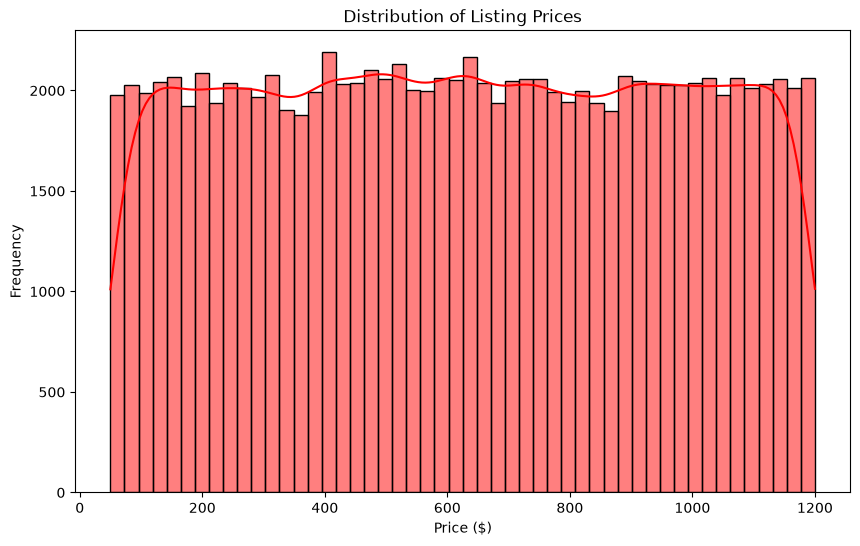

In [20]:
plt.figure(figsize=(10, 6)) 
sns.histplot(df['price'], bins=50, kde=True, color='red')  
# Set histogram color 
plt.title('Distribution of Listing Prices') 
plt.xlabel('Price ($)') 
plt.ylabel('Frequency') 
plt.show()

In [ ]:
The histogram shows a fairly even distribution of listing prices across different price ranges,
indicating no particular concentration of listings in any specific price range. 
The KDE line helps visualize this even spread more clearly, 
confirming that the dataset contains listings with a wide variety of prices.

ROOM TYPE ANALYSIS

Analyze the distribution of different room types.

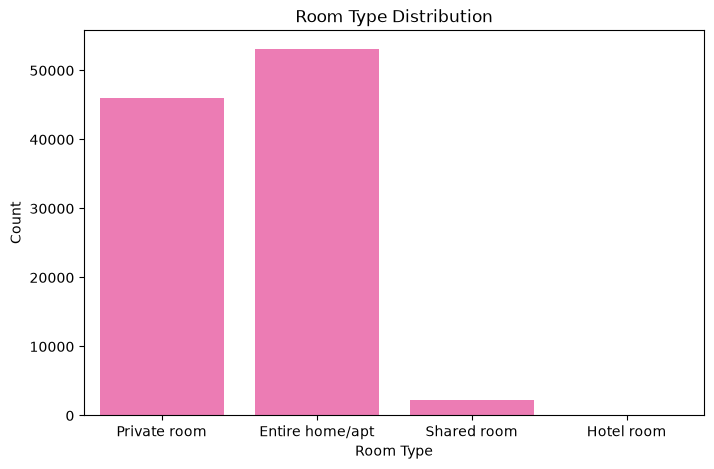

In [21]:
plt.figure(figsize=(8, 5)) 
sns.countplot(x='room type', data=df , color='hotpink') 
plt.title('Room Type Distribution') 
plt.xlabel('Room Type') 
plt.ylabel('Count') 
plt.show()

The count plot shows a clear distribution of the different room types available in the Airbnb dataset.
The majority of listings are for 'Entire home/apt' and 'Private room', with 'Shared room' and 'Hotel room' being much less common. 
This insight can be useful for understanding the availability and popularity of different types of accommodations on Airbnb.

Neighborhood Analysis

Examine how listings are distributed across different neighborhoods.

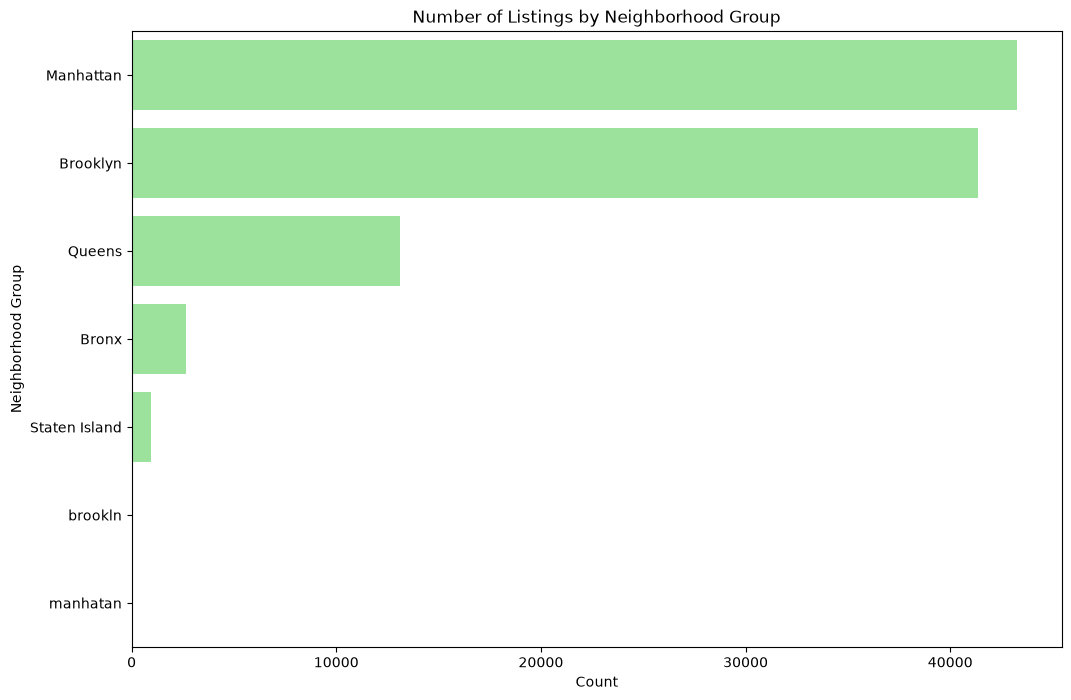

In [26]:
plt.figure(figsize=(12, 8)) 
sns.countplot(y='neighbourhood group', data=df,color="lightgreen" , order=df['neighbourhood group'].value_counts().index)
plt.title('Number of Listings by Neighborhood Group') 
plt.xlabel('Count') 
plt.ylabel('Neighborhood Group') 
plt.show()

In [ ]:
The count plot shows a clear distribution of the number of listings across different neighborhood groups.
    Manhattan and Brooklyn dominate the listings, suggesting they are prime locations for Airbnb.
    Queens, Bronx, and Staten Island have fewer listings, indicating less availability or popularity.

PRICE VS ROOM TYPE

Visualize the relationship between price and room type

C:\Users\HP\AppData\Local\Temp\ipykernel_16780\4262366262.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Room Type')


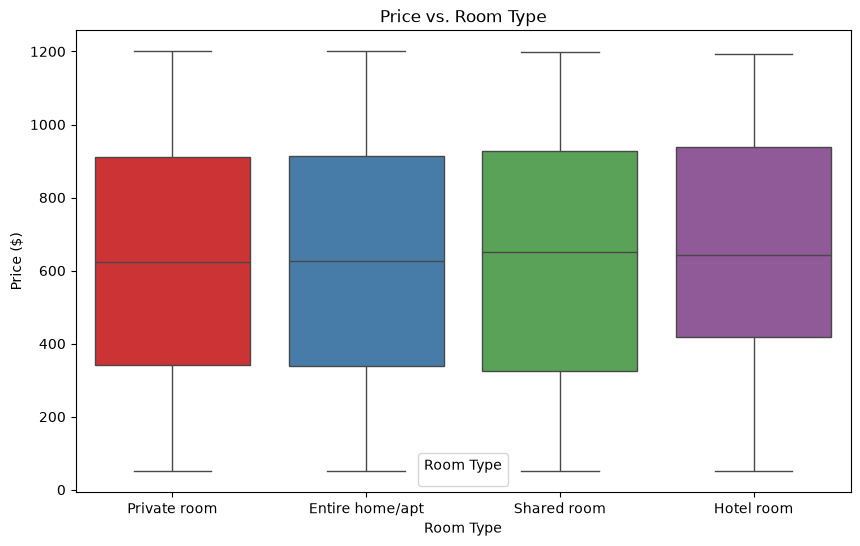

In [23]:
plt.figure(figsize=(10, 6)) 
sns.boxplot(x='room type', y='price', hue='room type', data=df, palette='Set1') 
plt.title('Price vs. Room Type') 
plt.xlabel('Room Type') 
plt.ylabel('Price ($)') 
plt.legend(title='Room Type') 
plt.show()

In [ ]:
Price vs. Room Type
The box plot provides a detailed view of how prices vary across different room types in the Airbnb dataset.
It shows that while 'Shared room' tends to have lower prices, 
'Private room', 'Entire home/apt', and 'Hotel room' have higher and more varied price ranges. 
This visualization helps in understanding the pricing dynamics for different types of accommodations on Airbnb.

REVIEWS OVER TIME

Plot the number of reviews over time.

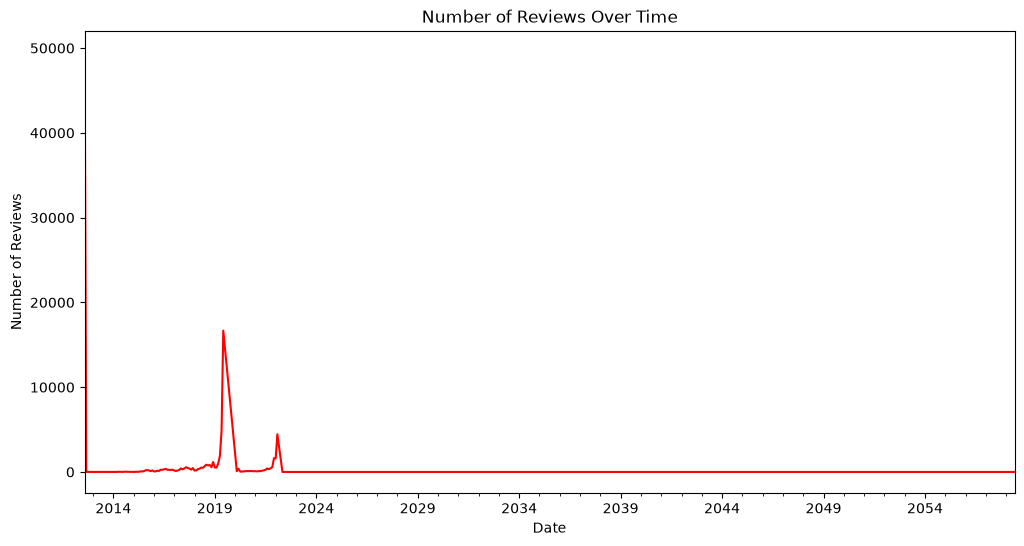

In [25]:
df['last review'] = pd.to_datetime(df['last review']) 
reviews_over_time = df.groupby(df['last review'].dt.to_period('M')).size() 
plt.figure(figsize=(12, 6))
reviews_over_time.plot(kind='line',color='red') 
plt.title('Number of Reviews Over Time') 
plt.xlabel('Date') 
plt.ylabel('Number of Reviews') 
plt.show()

In [ ]:
The line plot provides a clear visualization of the number of reviews over time. 
It helps identify trends and patterns in review activity, such as periods of high or low activity. 
This information can be useful for understanding the dynamics of user engagement and the popularity of Airbnb listings over time. 
The significant spikes and drops in reviews might be worth further investigation to understand the underlying causes, 
such as changes in Airbnb policies, market conditions, or external events.